In [159]:
#Import libraries and define Symbols
#%matplotlib widget
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45, BDF
from scipy.optimize import direct, Bounds
import time
from control import lqr, lqe
import scipy as sp

In [160]:
#Parameters
T = 2300                    #Thrust
P_max = 0.6                 #Max throttle percentage
m = 100                     #Mass
Iyy = (1/12) * m * 2        #Pitch moment of inertia
g = 9.8                     #Gravity
dNoz = 0.7                  #Distance from CoM to Nozzle
t_final = 65                #Final simulation time
control_frequency = 50      #Hertz
dt = 1/control_frequency    #Control time step

In [161]:
#Control matrices

#Continuous control matrices
Atc = np.zeros([6,6])
Atc[0,2] = 1
Atc[1,3] = 1
Atc[2,4] = -g
Atc[4,5] = 1

Btc = np.zeros([6,2])
Btc[2,0] = -g
Btc[3,1] = -T/m
Btc[5,0] = dNoz*m*g/Iyy

#Discrete control matrices
Concatenated = np.concatenate((np.concatenate((Atc, Btc), axis = 1), np.zeros((2,8))),axis=0)
Exp_Concat = np.round(sp.linalg.expm(Concatenated * dt))
Atd = Exp_Concat[:6,:6]
Btd = Exp_Concat[:6,6:]

In [162]:
#Trajectory
H = 100.0
V = 8.0
Ti = 22.0
Th = 10.0
Tf = 55.0
x1 = V / (T/m - g)
x2 = (2/V) * (H+V * x1 - 0.5* (T/m - g) * (x1**2) ) - Ti
x4 = Ti +Th
x5 = x4 + (Ti - x2)
X = V/(2*(Ti-x2))
x6 = (2/V) * (H+V * x5 - X* ((x5-x4) **2) ) - Tf
Y = V/(2*(Tf-x6))

def z_ref(t0):
    if t0< x1:
        return 0.5 * (T/m - g) * (t0 **2)
    elif (t0>x1) and (t0<x2):
        return V * (t0- x1) + 0.5 * (T/m - g) * (x1 **2)
    elif (t0>x2) and (t0<Ti):
        return -X * ((t0-Ti) **2) + H
    elif (t0>Ti) and (t0<x4):
        return H
    elif (t0>x4) and (t0<x5):
        return -X * ((t0-x4) ** 2) + H
    elif (t0>x5) and (t0<x6):
        return -V * (t0-x5) + H -X * ((x5-x4) ** 2)
    elif (t0>x6) and (t0<Tf):
        return Y * ((t0-Tf) ** 2)
    else:
        return 0

def dz_ref(t0):
    return (z_ref(t0+0.001) - z_ref(t0)) / 0.001


In [163]:
#LQR and Kalman filter

#LQR gain
Q = np.diag([1,100,10,800,100,500])
R = np.diag([0.001,1])
K, Ric, Eig = lqr(Atc, Btc, Q, R)

def LQR(t_hat, State_hat, u):
    x_hat, z_hat, dx_hat, dz_hat, theta_hat, dtheta_hat = State_hat
    gamma0, P0 = u

    #Set control parameters
    gamma, P = -K @ [x_hat, z_hat-z_ref(t_hat), dx_hat, dz_hat-dz_ref(t_hat), theta_hat, dtheta_hat]

    #Control limits
        
    #Throttle
    bP=1.0 #damping
    #max throttle rate
    dP = P-P0
    P = P0 + np.clip((dP/dt),-10,10)*dt / bP #update P with damping
    P = np.clip(P,0,P_max) #min/max throttle

    #Gimbal
    bgamma = 1.0 #gimbal damping
    #max gimbal rate
    dgamma = gamma-gamma0
    gamma = gamma0 + np.clip((dgamma/dt),-35, 35)*dt / bgamma #update P with damping
    gamma = np.clip(gamma, -0.22, 0.22) #min/max gimbal

    return [gamma, P]

#Process and measurement covariances
position_variance = 1e-10
velocity_variance = 1e-5
Q_kalman = np.diag([position_variance, position_variance, velocity_variance, velocity_variance, 1e-10, 1e-7])
R_kalman = np.diag([1, 1, 1, 1, 1, 1]) * 1e-5 
Q_d = np.identity(Q_kalman.shape[0]) + Q_kalman * dt
R_d = R_kalman / dt

def Kalman_Filter(observed_state, kalman_state, kalman_covariance, u):
    apriori_state = Atd@kalman_state + Btd@u
    apriori_covariance = Atd@kalman_covariance@Atd.T + Q_d
    kalman_gain = (apriori_covariance) @np.linalg.inv(apriori_covariance + R_d)
        
    aposteriori_state = apriori_state + kalman_gain@(observed_state - apriori_state)
    aposteriori_covariance = (np.identity(6) - kalman_gain)@apriori_covariance@(np.identity(6) - kalman_gain).T + kalman_gain@R_d@kalman_gain.T

    return [aposteriori_state, aposteriori_covariance]

In [174]:
#DiffEq Solver (BDF)

# Define the system of ODEs
def system(t, State):
    global P
    global gamma

    x, z, dx, dz, theta, dtheta = State

    ddx =  - (1-P)*T/m * np.sin(theta + gamma)
    ddz =  (1-P)*T/m * np.cos(theta + gamma) - g
    ddtheta =  (1-P)*dNoz*T/Iyy * np.sin(gamma)

    return [dx, dz, ddx, ddz, dtheta, ddtheta]  

# Time span
t_span = (0, t_final) 

#Solution Data
t_vals, State_vals, gamma_vals, P_vals = [], [], [], []

#End status (0=full run, 1=took too long, 2=crashed)
status = 0

# Initial conditions
initial_state = [0,0, 0,0, 0.0,4]
gamma = 0
P=0
kalman_times = [0]
kalman_states = [np.array(initial_state)]
kalman_covariances = [np.zeros((6,6))]
t_hat = 0

#Start Solver
start_time = time.time()
solver = BDF(system, t_span[0], initial_state, t_span[1], max_step=dt)

while solver.status == "running":
    #Step solver and save data
    solver.step()

    # add disturbance
    w = np.random.multivariate_normal(np.zeros(6), Q_kalman)
    solver.y = solver.y + w*(solver.t - solver.t_old)

    t_vals.append(solver.t)
    State_vals.append(solver.y.copy())
    gamma_vals.append(gamma)
    P_vals.append(P)

    #Controls
    if (solver.t - t_hat > dt):
        #Measurement
        t_hat = solver.t
        observed_state = solver.y
        v = np.random.multivariate_normal(np.zeros(6), R_kalman)
        observed_state += v

        #Kalman filter
        aposteriori_state, aposteriori_covariance = Kalman_Filter(observed_state, kalman_states[-1], kalman_covariances[-1], [gamma, P])
        kalman_states.append(aposteriori_state)
        kalman_covariances.append(aposteriori_covariance)
        kalman_times.append(solver.t)

        #LQR
        gamma, P = LQR(t_hat, kalman_states[-1], [gamma, P])

    #Progress bar
    print("t " + str(round(solver.t, 2)) + " / " + str(solver.t_bound) + "           ", end="\r")

    #End conditions
    if time.time() - start_time > 240:   
        solver.status = "stopped"
        status = 1
        break
    if (State_vals[-1][1] < 0):
        solver.status = "stopped"    
        status = 2
        break

#Timestamped data
State_vals = np.array(State_vals).T
kalman_states = np.array(kalman_states).T

Status: 0


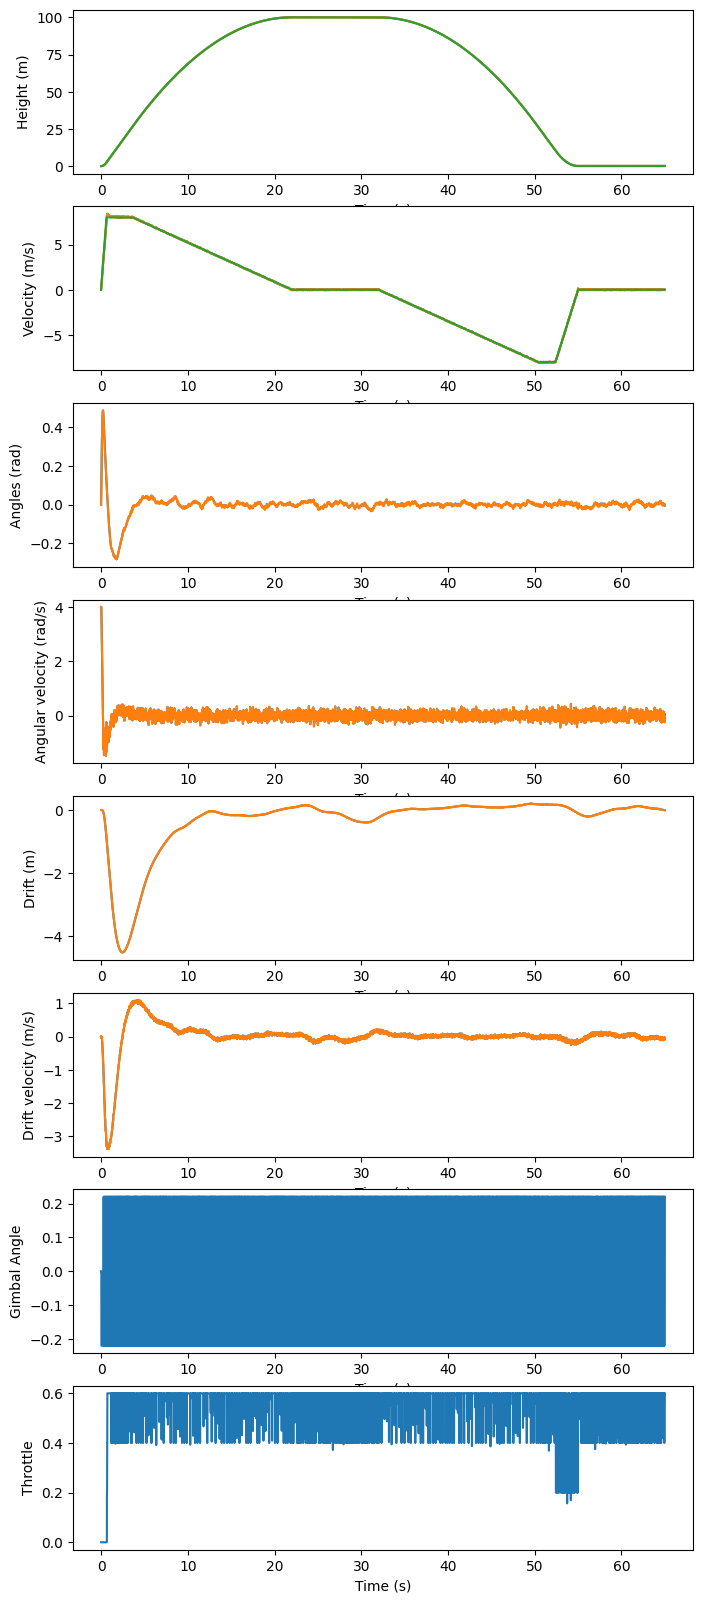

In [175]:
#Plot the trajectory
fig, ax = plt.subplots(nrows=6 + 2, ncols=1,figsize=(8, 20))
for i in range(6 + 2):
    ax[i].set_xlabel("Time (s)")

def plot_noisy_value(ax, ts, vals, noises):
    # pass10
    ax.plot(ts, vals)
    # ax.scatter(ts, vals)
    ax.fill_between(ts, vals - noises, vals + noises, alpha = 0.2, color="orange")

ax[0].plot(t_vals, State_vals[1])
plot_noisy_value(ax[0], kalman_times, kalman_states[1], [c[1, 1] for c in kalman_covariances])
ax[0].plot(t_vals, [z_ref(i) for i in t_vals])

ax[1].plot(t_vals, State_vals[3])
plot_noisy_value(ax[1], kalman_times, kalman_states[3], [c[3, 3] for c in kalman_covariances])
ax[1].plot(t_vals, [dz_ref(i) for i in t_vals])

ax[2].plot(t_vals, State_vals[4])
plot_noisy_value(ax[2], kalman_times, kalman_states[4], [c[4, 4] for c in kalman_covariances])
ax[3].plot(t_vals, State_vals[5])
plot_noisy_value(ax[3], kalman_times, kalman_states[5], [c[5, 5] for c in kalman_covariances])
ax[4].plot(t_vals, State_vals[0])
plot_noisy_value(ax[4], kalman_times, kalman_states[0], [c[0, 0] for c in kalman_covariances])
ax[5].plot(t_vals, State_vals[2])
plot_noisy_value(ax[5], kalman_times, kalman_states[2], [c[2, 2] for c in kalman_covariances])
ax[6].plot(t_vals, gamma_vals)
ax[7].plot(t_vals, P_vals)

ax[0].set_ylabel("Height (m)")
ax[1].set_ylabel("Velocity (m/s)")
ax[2].set_ylabel("Angles (rad)")
ax[3].set_ylabel("Angular velocity (rad/s)")
ax[4].set_ylabel("Drift (m)")
ax[5].set_ylabel("Drift velocity (m/s)")
ax[6].set_ylabel("Gimbal Angle")
ax[7].set_ylabel("Throttle")

#Print status (0=full run, 1=took too long, 2=crashed)
print(f"Status: {status}")

#Show plots
plt.show() # type: ignore

In [ ]:
import matplotlib as mpl
import matplotlib.animation as mpa

RECT_WIDTH = 0.2
RECT_HEIGHT = 1.0

# ie 1 is real time, 10 is 10x as fast
# SPEED_FACTOR = 10.0

fig, axs = plt.subplots(nrows=1, ncols=2)
ax = axs[0]
ax.set_aspect('equal')

# Set reasonable view limits
ax.set_xlim(min(State_vals[0]) - 1, max(State_vals[0]) + 1)
plot_width = (max(State_vals[0]) + 1) - (min(State_vals[0]) - 1)
# ax.set_xlim(-100, 100)
ax.set_ylim(-1, max(State_vals[1]) + 1)

rect = mpl.patches.Rectangle((0, 0), RECT_WIDTH, RECT_HEIGHT, angle=0, fill=True, color="blue")
kalman_rect = mpl.patches.Rectangle((0, 0), RECT_WIDTH, RECT_HEIGHT, angle=0, fill=True, alpha=0.75, color="orange")
reference_rect = mpl.patches.Rectangle((0, 0), plot_width, 0.2, angle=0, fill=True, alpha=0.25, color="green")
ax.add_patch(rect)
ax.add_patch(kalman_rect)
ax.add_patch(reference_rect)

time_text = ax.text(
    0.0, 1.1, "", transform=ax.transAxes, ha="left", va="top"
)

ax.plot(State_vals[0], State_vals[1], alpha=0.5, lw=0.5)

zoom_ax = axs[1]
zoom_ax.set_xlim(-2, 2)
zoom_ax.set_ylim(-2, 2)
# zoom_ax.set_xlim(min(kalman_states[0] - State_vals[0]) - 1, max(kalman_states[0] - State_vals[0]) + 1)
# zoom_ax.set_ylim(min(kalman_states[1] - State_vals[1]) - 1, max(kalman_states[1] - State_vals[1]) + 1)

zoom_rect = mpl.patches.Rectangle((0, 0), RECT_WIDTH, RECT_HEIGHT, angle=0, fill=True, color="blue")
zoom_kalman_rect = mpl.patches.Rectangle((0, 0), RECT_WIDTH, RECT_HEIGHT, angle=0, fill=True, alpha=0.75, color="orange")
zoom_reference_rect = mpl.patches.Rectangle((0, 0), plot_width, 0.05, angle=0, fill=True, alpha=0.25, color="green")
zoom_ax.add_patch(zoom_rect)
zoom_ax.add_patch(zoom_kalman_rect)
zoom_ax.add_patch(zoom_reference_rect)

dt_s = 1 / 30.0

def update_rect(rect, cx, cz, theta):
    # Compute bottom-left corner from center
    bl_x = cx - RECT_WIDTH / 2
    bl_z = cz - RECT_HEIGHT / 2

    # Update rectangle geometry
    rect.set_xy((bl_x, bl_z))
    rect.angle = theta

def update(frame):
    t = dt_s * frame
    print(f"{t:.2f} / {t_vals[-1]:.2f}      ", end="\r")
    t_idx = np.searchsorted(t_vals, t)

    update_rect(rect, State_vals[0][t_idx], State_vals[1][t_idx], State_vals[4][t_idx])
    kalman_t_idx = np.searchsorted(kalman_times, t)
    update_rect(kalman_rect, kalman_states[0][kalman_t_idx], kalman_states[1][kalman_t_idx], kalman_states[4][kalman_t_idx])
    reference_rect.set_xy((-plot_width / 2, z_ref(t)))

    update_rect(zoom_rect, 0, 0, State_vals[4][t_idx])
    update_rect(zoom_kalman_rect, kalman_states[0][kalman_t_idx] - State_vals[0][t_idx], kalman_states[1][kalman_t_idx] - State_vals[1][t_idx], kalman_states[4][kalman_t_idx])
    zoom_reference_rect.set_xy((-plot_width / 2, z_ref(t) - State_vals[1][t_idx]))
    
    time_text.set_text(f"t = {t_vals[t_idx]:.2f} s frame = {frame}")

    return rect, kalman_rect, reference_rect, zoom_rect, zoom_kalman_rect, zoom_reference_rect, time_text

print(t_vals[-1])
print(len(t_vals))
print(int(t_vals[-1] / dt_s))

anim = mpa.FuncAnimation(
    fig,
    update,
    frames=int(t_vals[-1] / dt_s),
    interval=dt_s * 1000,
    blit=True
)

anim.save("log/anim.mp4")
# plt.show()



In [ ]:
#Plot the control
fig, ax = plt.subplots(nrows=2, ncols=1,figsize=(8, 10))

ax[0].set_xlabel("Time (s)")
ax[1].set_xlabel("Time (s)")

ax[0].plot(t_vals, gamma_vals)
ax[1].plot(t_vals, P_vals)


ax[0].set_ylabel("Gamma (rad)")
ax[1].set_ylabel("P (%)")

#Show plots
plt.show()

In [ ]:
np.savetxt("log/times.csv", t_vals, delimiter=",")
np.savetxt("log/states.csv", State_vals, delimiter=",")
np.savetxt("log/kalmans.csv", kalman_states, delimiter=",")
np.savetxt("log/kalman_times.csv", kalman_times, delimiter=",")
np.savetxt("log/gammas.csv", gamma_vals, delimiter=",")
np.savetxt("log/throttles.csv", P_vals, delimiter=",")

In [ ]:
t_vals = np.loadtxt("log/times.csv", delimiter=",")
State_vals = np.loadtxt("log/states.csv", delimiter=",")
kalman_states = np.loadtxt("log/kalmans.csv", delimiter=",")
kalman_times = np.loadtxt("log/kalman_times.csv", delimiter=",")
gamma_vals = np.loadtxt("log/gammas.csv", delimiter=",")
P_vals = np.loadtxt("log/throttles.csv", delimiter=",")